Intermediate Deep Learning - Deep Reinforcement Learning
# Session 5: Proximal Policy Optimization (PPO)

In this TD, we will implement the Proximal Policy Optimization (PPO) algorithm, by building upon the code we wrote for A2C in the previous TD.

### Task 0 ⚙️: 

**Instructions:**

1. Import necessary libraries and packages

In [1]:
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch

import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym


## Part 1: Implementation of PPO Algorithm
---


**Reminder : The PPO Algorithm:**
1.	Collect trajectories by executing the current policy in the environment.
2.	Compute the returns and advantages for each timestep using GAE.
3.	Update the policy parameters by maximizing the clipped surrogate objective and minimizing the critic loss.

**PPO Update with Clipped Objective, GAE, and Entropy Regularization:**
$$
J^{\text{CLIP+ENT}}(\theta_A)
=
\mathbb{E}_t \Big[
\min \big(
r_t(\theta_A) , A^{\text{GAE}}\pi (s_t, a_t),
\text{clip}(r_t(\theta_A), 1 - \epsilon, 1 + \epsilon)
, A^{\text{GAE}}_\pi (s_t, a_t)
\big)
+ \beta H_t
\Big]
$$


and the policy parameters are updated by gradient ascent:
$$
\theta_A \leftarrow \theta_A + \alpha \, \nabla_{\theta_A} J^{\text{CLIP+ENT}}(\theta_A)
$$

where the importance ratio is
$$
r_t(\theta_A) =
\frac{
\pi_{\theta_A}(a_t \mid s_t)
}{
\pi_{\theta_{\text{old}}}(a_t \mid s_t)
}.
$$

and the critic is updated by minimizing

$$
    L(\theta_C) = 
    \frac{1}{2} 
    \sum_{t=0}^{T} 
    \left(
        V^{\text{target}}(s_t) - V_{\theta_C}(s_t)

    \right)^2,
    \quad
    V^{\text{target}}(s_t) = \text{no\_grad}(A^{\text{GAE}}_\pi (s_t, a_t) + V_{\theta_C}(s_t))
$$

- $\theta_A$: Policy parameters (actor network weights)
- $\theta_C$: Value function parameters (critic network weights)
- $\pi_{\theta_A}(a_t \mid s_t)$: Current policy probability of taking action $a_t$ in state $s_t$
- $\pi_{\theta_{\text{old}}}(a_t \mid s_t)$: Behavior policy used to collect data
- $r_t(\theta_A)$: Probability ratio between new and old policies
- $\epsilon$: Clipping coefficient limiting policy deviation
- $A^{\text{GAE}}_\pi (s_t, a_t)$: Generalized Advantage Estimation
- $H_t$: Entropy of the policy at time $t$
- $\beta$: Entropy regularization coefficient encouraging exploration
- $\gamma$: Discount factor
- $\lambda$: GAE decay parameter controlling bias–variance trade-off
- $\alpha$: Learning rate for the actor
- $\text{clip}(r_t, 1-\epsilon, 1+\epsilon)$: Ensures conservative policy updates for stability

**Remark**
In this TD, we will try to implement the PPO algorithm with the clipped objective, without old-policy network. This design choice will have some implications on the implementation of the PPO agent, especially in the way we compute the importance sampling ratio.


### Task 1.1 📝: Implement the ActorCriticNetwork class


**Instructions:** 
1. Since PPO builds upon A2C, start by copying the `ActorCriticNetwork` class from TD5.
2. Is there any modification on the network architecture needed for PPO? If so, implement them.

In [2]:
class ActorCriticNetwork(nn.Module):
    def __init__(self, state_size, n_actions, hidden_size=128):
        super().__init__()
        self.shared = nn.Sequential(
            nn.Linear(state_size, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, hidden_size),
            nn.Tanh(),
        )
        self.actor = nn.Linear(hidden_size, n_actions)
        self.critic = nn.Linear(hidden_size, 1)

    def forward(self, x):

        features = self.shared(x)

        logits = self.actor(features)
        action_probs = torch.softmax(logits, dim=-1)

        state_value = self.critic(features)
        
        return action_probs, state_value

### Task 1.2 📝: Create the PPO Agent


**Instructions:** 
1. Adapt the A2CAgent class implemented in the previous TD to create the PPOAgent class.
2. Which new hyperparameters do we add to the PPO agent compared to the A2C agent?
3. In the A2C agent, we stored certain variables in memory buffers during rollouts. For PPO, which variables do we need to store in the memory buffers during rollouts, and why? Add any necessary modifications to the memory storage and update methods.


<details>
<summary>Hint 💡</summary>

Consider the fact that the old policy is not maintained as a separate network in this implementation of PPO. How does this affect the computation of the surrogate ratio during the update step?
</details>


### Task 1.3 📝: Action selection


**Instructions:** 
1. The action selection in PPO is amost identical to that in A2C. Is there any difference? If so, implement the necessary changes in the `choose_action` method.


<details>
<summary>Hint 💡</summary>

- Since PPO does not maintain a separate old-policy network, we need to ensure that we also return the log probability of the selected action along with the action and value estimate. This log probability will be used later to compute the importance sampling ratio during the PPO update.
</details>

In [4]:
class PPOAgent:
    def __init__(
        self, lr=3e-4, gamma=0.99, state_size=4, n_actions=2,
        gae_lambda=0.95, entropy_beta=0.01, clip_epsilon=0.2, ppo_epochs=10, batch_size=64
    ):
        
        # Hyperparameters
        self.lr = lr
        self.gamma = gamma
        self.gae_lambda = gae_lambda
        self.entropy_beta = entropy_beta
        self.clip_epsilon = clip_epsilon
        self.ppo_epochs = ppo_epochs
        self.batch_size = batch_size

        # Environment parameters
        self.state_size = state_size
        self.n_actions = n_actions

        # Device configuration
        if torch.cuda.is_available():
            self.device = torch.device("cuda")  # GPU
        # elif torch.backends.mps.is_available():
        #     self.device = torch.device("mps")  # Metal Performance Shaders for Mac
        else:
            self.device = torch.device("cpu")
        print(f"Using device: {self.device}")

        # Create policy network
        self.network = ActorCriticNetwork(state_size, n_actions).to(self.device)

        # Optimizer
        self.optimizer = optim.Adam(self.network.parameters(), lr=lr)

        # Memory buffers
        self.reset_memory()

    def reset_memory(self):
        """Clear rollout buffers."""
        self.states = []
        self.actions = []
        self.rewards = []
        self.values = []
        self.dones = []
        self.log_probs = []

    def choose_action(self, state):
        """
        Sample an action from the current policy given the state
        """
        state_tensor = torch.tensor(state, dtype=torch.float32, device=self.device).unsqueeze(0)

        # Get action probabilities from policy
        with torch.no_grad():
            probs, value = self.network(state_tensor)

        # Create categorical distribution
        dist = torch.distributions.Categorical(probs=probs)

        # Sample action
        action = dist.sample()  # tensor([a])
        log_prob = dist.log_prob(action)  # tensor([log_prob])
        return action.item(), value.item(), log_prob.item()

    def store(self, state, action, reward, value, done, log_probs):
        """Store a transition; done marks termination OR time-limit truncation.

        The training loop adds the bootstrap value to time-limit rewards.
        """
        self.states.append(state)
        self.actions.append(action)
        self.rewards.append(reward)
        self.values.append(value)
        self.dones.append(done)
        self.log_probs.append(log_probs)

    def compute_gae(self, next_value):
        """
        Compute returns and advantages using either
        GAE (Generalized Advantage Estimation)
        """
        rewards = np.array(self.rewards, dtype=np.float32)
        values = np.array(self.values + [next_value], dtype=np.float32)
        dones = np.array(self.dones, dtype=np.float32)

        T = len(rewards)
        returns = np.zeros(T, dtype=np.float32)
        advantages = np.zeros(T, dtype=np.float32)

        gae = 0.0
        for t in reversed(range(T)):
            delta = rewards[t] + self.gamma * values[t + 1] * (1.0 - dones[t]) - values[t]
            gae = delta + self.gamma * self.gae_lambda * (1.0 - dones[t]) * gae
            advantages[t] = gae

            # Compute returns
            returns[t] = advantages[t] + values[t]

        return returns, advantages

    def update(self, next_value):
        """Perform one PPO update step."""
        if len(self.states) == 0:
            return {"actor_loss": 0.0, "critic_loss": 0.0}

        returns, advantages = self.compute_gae(next_value)

        # Convert to tensors
        states = torch.tensor(np.array(self.states), dtype=torch.float32, device=self.device) # (N, state_size)
        actions = torch.tensor(np.array(self.actions), dtype=torch.int64, device=self.device)   # (N,)
        returns = torch.tensor(returns, dtype=torch.float32, device=self.device)    # (N,)
        advantages = torch.tensor(advantages, dtype=torch.float32, device=self.device) # (N,)
        old_log_probs = torch.tensor(np.array(self.log_probs), dtype=torch.float32, device=self.device) # (N,)

        # Normalize only when the rollout has at least two samples.
        if advantages.numel() > 1:
            advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)   # (N,)

        total_actor_loss = 0
        total_critic_loss = 0
        updates = 0
        
        for _ in range(self.ppo_epochs):
            # Shuffle the indices
            indices = torch.randperm(len(states))
            
            for start in range(0, len(states), self.batch_size):
                end = start + self.batch_size if start + self.batch_size < len(states) else len(states)
                idx = indices[start:end]
                
                batch_states = states[idx]
                batch_actions = actions[idx]
                batch_old_log_probs = old_log_probs[idx]
                batch_returns = returns[idx]
                batch_advantages = advantages[idx]
                
                # Forward pass
                action_probs, values = self.network(batch_states) # (batch_size, n_actions), (batch_size, 1)
                dist = torch.distributions.Categorical(action_probs) # (batch_size, n_actions)
                log_probs = dist.log_prob(batch_actions)  # (batch_size,)
                entropy = dist.entropy().mean() # scalar
                
                # PPO loss computation
                ratio = torch.exp(log_probs - batch_old_log_probs)  # (batch_size,)
                surr1 = ratio * batch_advantages
                surr2 = torch.clamp(ratio, 1.0 - self.clip_epsilon, 1.0 + self.clip_epsilon) * batch_advantages
                actor_loss = -torch.min(surr1, surr2).mean()
                
                critic_loss = F.mse_loss(values.squeeze(-1), batch_returns)
                
                loss = actor_loss + 0.5 * critic_loss - self.entropy_beta * entropy # Total loss
                
                self.optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(self.network.parameters(), 0.5)
                self.optimizer.step()
                
                total_actor_loss += actor_loss.item()
                total_critic_loss += critic_loss.item()
                updates += 1
        
        self.reset_memory()
        
        return {
            'actor_loss': total_actor_loss / updates,
            'critic_loss': total_critic_loss / updates
        }


### Task 1.4 📝: Implement policy update method

PPO uses a different update mechanism compared to A2C, involving the clipped surrogate objective and multiple epochs of updates.
- In this implementation, we will sample mini-batches from the collected data for multiple epochs of updates. Instead of using the entire batch of collected data at once, we will divide it into smaller mini-batches and perform updates on each mini-batch for a specified number of epochs. The order of the samples will be randomized in each epoch to ensure diverse updates.

**Instructions:** 
1. Read the provided code that generates a random permutation of indices at the beginning of each training epoch. No implementation is required for this step.
2. Read the provided code that creates mini-batches by slicing the shuffled indices into chunks of size `batch_size`. No implementation is required for this step.
3. Compare to randomly sampling mini-batches, what is the advantage of shuffling and slicing?
4. There are mistakes in the forward pass section, correct them.
5. For each mini-batch, calculate the probability ratios using the log probabilities.
6. Compute the clipped surrogate objective. Use this to compute the actor loss for the mini-batch.
7. Will the surrogate objective be clipped for the first time the policy is updated? Why or why not?


<details>
<summary>Toolbox 🛠️</summary>

- Use `torch.randperm` to generate a random permutation of indices for shuffling the data.
```python
indices = torch.randperm(len(states))
```

- Use `torch.exp` to compute the exponentials of the log probabilities to get the probability ratios.
```python
e_x = torch.exp(x)
```

- Use `torch.clamp` to clip the probability ratios within the specified range.
```python
clipped_x = torch.clamp(x, lower_bound, upper_bound)
```

</details>

## Part 2: Training Loop
---

### Task 2.1 🍃: Implement training function

**Instructions:**
1. Run the cell to define the training function. We train for `episodes` episodes and update the agent every `update_freq` environment steps.
2. As in TD5, pass hyperparameters directly to `train_agent`. PPO additionally uses `clip_epsilon`, `ppo_epochs` and `batch_size`.
3. At a time limit, bootstrap from the final observation and stop GAE at the episode boundary. Update the final partial rollout when training ends.


In [5]:
def train_agent(episodes=1000, update_freq=2048, env_id="LunarLander-v3",
                lr=3e-4, gamma=0.99, gae_lambda=0.95, entropy_beta=0.01,
                clip_epsilon=0.2, ppo_epochs=10, batch_size=64, seed=31):
    """
    Train a PPO agent on the selected environment.
    PPO collects 'update_freq' transitions before its mini-batch updates.
    """
    if episodes < 1 or update_freq < 1:
        raise ValueError("episodes and update_freq must be positive.")

    # Seed the network initialization and action sampling.
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Create environment
    env = gym.make(env_id)

    # Environment parameters
    sample_state, _ = env.reset()
    state_size = len(sample_state)
    n_actions = env.action_space.n

    print(f"State size: {state_size}, Number of actions: {n_actions}")

    # Create PPO agent
    agent = PPOAgent(
        state_size=state_size,
        n_actions=n_actions,
        lr=lr,
        gamma=gamma,
        gae_lambda=gae_lambda,
        entropy_beta=entropy_beta,
        clip_epsilon=clip_epsilon,
        ppo_epochs=ppo_epochs,
        batch_size=batch_size,
    )

    rewards_history = []
    actor_loss_history = []
    critic_loss_history = []
    
    print(f"Training PPO on {env_id} for {episodes} episodes...")
    print("Starting training...")
    print("=" * 60)

    # Training loop
    steps_since_update = 0
    for ep in range(episodes):
        state, _ = env.reset(seed=seed if ep == 0 else None)
        done = False
        ep_reward = 0.0

        while not done:
            action, value, log_prob = agent.choose_action(state)
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            # PPO rollouts can span episodes. Bootstrap a time limit from its
            # final observation, then stop GAE at the episode boundary.
            stored_reward = reward
            if truncated and not terminated:
                with torch.no_grad():
                    next_tensor = torch.as_tensor(next_state, dtype=torch.float32, device=agent.device).unsqueeze(0)
                    stored_reward += agent.gamma * agent.network(next_tensor)[1].item()
            agent.store(state, action, stored_reward, value, done, log_prob)
            state = next_state
            ep_reward += reward
            steps_since_update += 1

            # Update a full rollout, or the final partial rollout of training.
            if steps_since_update >= update_freq or (done and ep + 1 == episodes):
                # Time-limit bootstrapping is already included in stored_reward.
                with torch.no_grad():
                    next_tensor = torch.as_tensor(next_state, dtype=torch.float32, device=agent.device).unsqueeze(0)
                    next_value = 0.0 if done else agent.network(next_tensor)[1].item()
                losses = agent.update(next_value)
                steps_since_update = 0
                actor_loss_history.append(losses["actor_loss"])
                critic_loss_history.append(losses["critic_loss"])

        rewards_history.append(ep_reward)

        if (ep + 1) % 20 == 0:
            avg100 = np.mean(rewards_history[-100:])
            print(f"Ep {ep+1}: Avg100 = {avg100:.2f}, Last = {ep_reward:.2f}")

    env.close()
    print("=" * 60)
    print("Training complete!")
    return agent, rewards_history, actor_loss_history, critic_loss_history

## Part 3: Testing
---

### Task 3.1 🍃: Test function

**Instructions:** 
1. The testing function is implemented for you. You just need to set the `render` parameter to `True` when calling the function to visualize the agent's performance.

In [6]:
def test_agent(agent, env_id="LunarLander-v3", episodes=5, render=True):
    """Run a trained PPO agent in test mode."""

    env = gym.make(env_id, render_mode="human" if render else None)
    for ep in range(episodes):
        state, _ = env.reset()
        done = False
        total_r = 0.0
        while not done:
            s_t = torch.as_tensor(state, dtype=torch.float32, device=agent.device).unsqueeze(0)
            
            with torch.no_grad():
                action_probs, _ = agent.network(s_t)

            # During testing, use the most probable action
            action = int(torch.argmax(action_probs, dim=-1).item())
            state, r, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            total_r += r
        print(f"Test Episode {ep+1}: {total_r:.2f}")
    env.close()

## Part 4: Visualization
---

### Task 4.1 🍃: Visualization function

**Instructions:** 
1. Run the provided visualization function. The left column shows raw curves and the right column shows moving averages (default window: 100). The three rows show training rewards, actor losses, and critic losses. Rewards are indexed by episode; losses are indexed by agent update.

In [7]:
def _moving_avg(x, window):
    """Return the moving average aligned with the original sample indices."""
    x = np.asarray(x, dtype=float)
    if len(x) < window or window == 1:
        return np.arange(len(x)), x
    moving_avg = np.convolve(x, np.ones(window) / window, mode="valid")
    return np.arange(window - 1, len(x)), moving_avg


def plot_results(
    rewards,
    actor_losses=None,
    critic_losses=None,
    reward_window=100,
    loss_window=100,
    solved_y=200,
    save_path=None,
    loss_log_scale=False,
):
    """Plot raw curves on the left and moving averages on the right.

    Rewards are recorded per episode; losses are recorded per agent update.
    Short histories are displayed without smoothing.
    """
    if reward_window < 1 or loss_window < 1:
        raise ValueError("Moving-average windows must be positive.")

    rows = [(rewards, "Train Reward", "Episode", "Total Reward", "Avg Reward", reward_window)]
    if actor_losses is not None:
        rows.append((actor_losses, "Actor Loss", "Update", "Loss", "Avg Loss", loss_window))
    if critic_losses is not None:
        rows.append((critic_losses, "Critic Loss", "Update", "Loss", "Avg Loss", loss_window))

    fig, axes = plt.subplots(len(rows), 2, figsize=(14, 4.6 * len(rows)), squeeze=False)

    for row, (values, title, xlabel, ylabel, avg_ylabel, window) in enumerate(rows):
        raw_ax, avg_ax = axes[row]

        # Raw values (left column).
        raw_ax.plot(values, alpha=0.4)
        raw_ax.set_title(f"{title} per {xlabel}")
        raw_ax.set_ylabel(ylabel)

        # Moving average (right column), aligned with the original indices.
        indices, moving_avg = _moving_avg(values, window)
        avg_ax.plot(indices, moving_avg)
        if len(values) >= window and window > 1:
            avg_ax.set_title(f"Moving Avg {title} (window={window})")
        else:
            avg_ax.set_title(f"{title} (no smoothing)")
        avg_ax.set_ylabel(avg_ylabel)

        for ax in (raw_ax, avg_ax):
            ax.set_xlabel(xlabel)
            ax.grid(True)
            if row == 0:
                if solved_y is not None:
                    ax.axhline(solved_y, color="gray", linestyle="--", linewidth=1,
                               label=f"Reward reference ({solved_y:g})")
                    ax.legend()
            else:
                ax.axhline(0, color="gray", linestyle="--", linewidth=1)
                if loss_log_scale:
                    # Actor losses may be negative, so a signed log scale is needed.
                    ax.set_yscale("symlog")

    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150)
    plt.show()


## Part 5: Execution
---

### Task 5.1 🚀: Train and Evaluate the Agent

**Instructions:**
1. Select an environment (e.g., 'CartPole-v1', 'Blackjack-v1' or 'LunarLander-v3'). 
2. The `solved_y` parameter in the `plot_results` function can be adjusted based on the environment chosen.
    - For 'CartPole-v1', set `solved_y` to 500.
    - For 'Blackjack-v1', set `solved_y=None`; a zero mean reward is not a suitable success threshold.
    - For 'LunarLander-v3', set `solved_y` to 200.
3. Run `train_agent` to train the agent.
4. Plot training results using `plot_results`.
5. Run `test_agent` to evaluate the trained agent.
6. Interpret the results.
7. Change environment and compare the results to see how PPO performs across different tasks. Compare the results with other algorithms like A2C or DQN implemented during previous sessions.

Pass each environment's hyperparameters directly to `train_agent`, as in TD5. CartPole uses the tuned settings below; Blackjack keeps its original settings after comparison. Detailed experiments are available in [the tuning report](ppo_tuning/other_envs/REPORT.md). The five rendered test episodes are demonstrations, not a reliable estimate of Blackjack's average reward.


State size: 8, Number of actions: 4
Using device: cpu
Training PPO on LunarLander-v3 for 3000 episodes...
Starting training...
Ep 20: Avg100 = -222.30, Last = -403.31
Ep 40: Avg100 = -214.72, Last = -146.73
Ep 60: Avg100 = -196.21, Last = -127.90
Ep 80: Avg100 = -190.23, Last = -51.04
Ep 100: Avg100 = -196.08, Last = -252.68
Ep 120: Avg100 = -209.70, Last = -257.87
Ep 140: Avg100 = -217.61, Last = -235.21
Ep 160: Avg100 = -233.50, Last = -398.64
Ep 180: Avg100 = -244.55, Last = -201.33
Ep 200: Avg100 = -240.43, Last = -437.06
Ep 220: Avg100 = -213.98, Last = -198.83
Ep 240: Avg100 = -192.07, Last = -87.93
Ep 260: Avg100 = -175.43, Last = -114.20
Ep 280: Avg100 = -154.77, Last = -134.11
Ep 300: Avg100 = -140.51, Last = -135.37
Ep 320: Avg100 = -140.10, Last = -116.99
Ep 340: Avg100 = -139.69, Last = -205.71
Ep 360: Avg100 = -135.42, Last = -118.14
Ep 380: Avg100 = -138.48, Last = -113.87
Ep 400: Avg100 = -147.76, Last = -168.66
Ep 420: Avg100 = -139.05, Last = -123.68
Ep 440: Avg100 = -

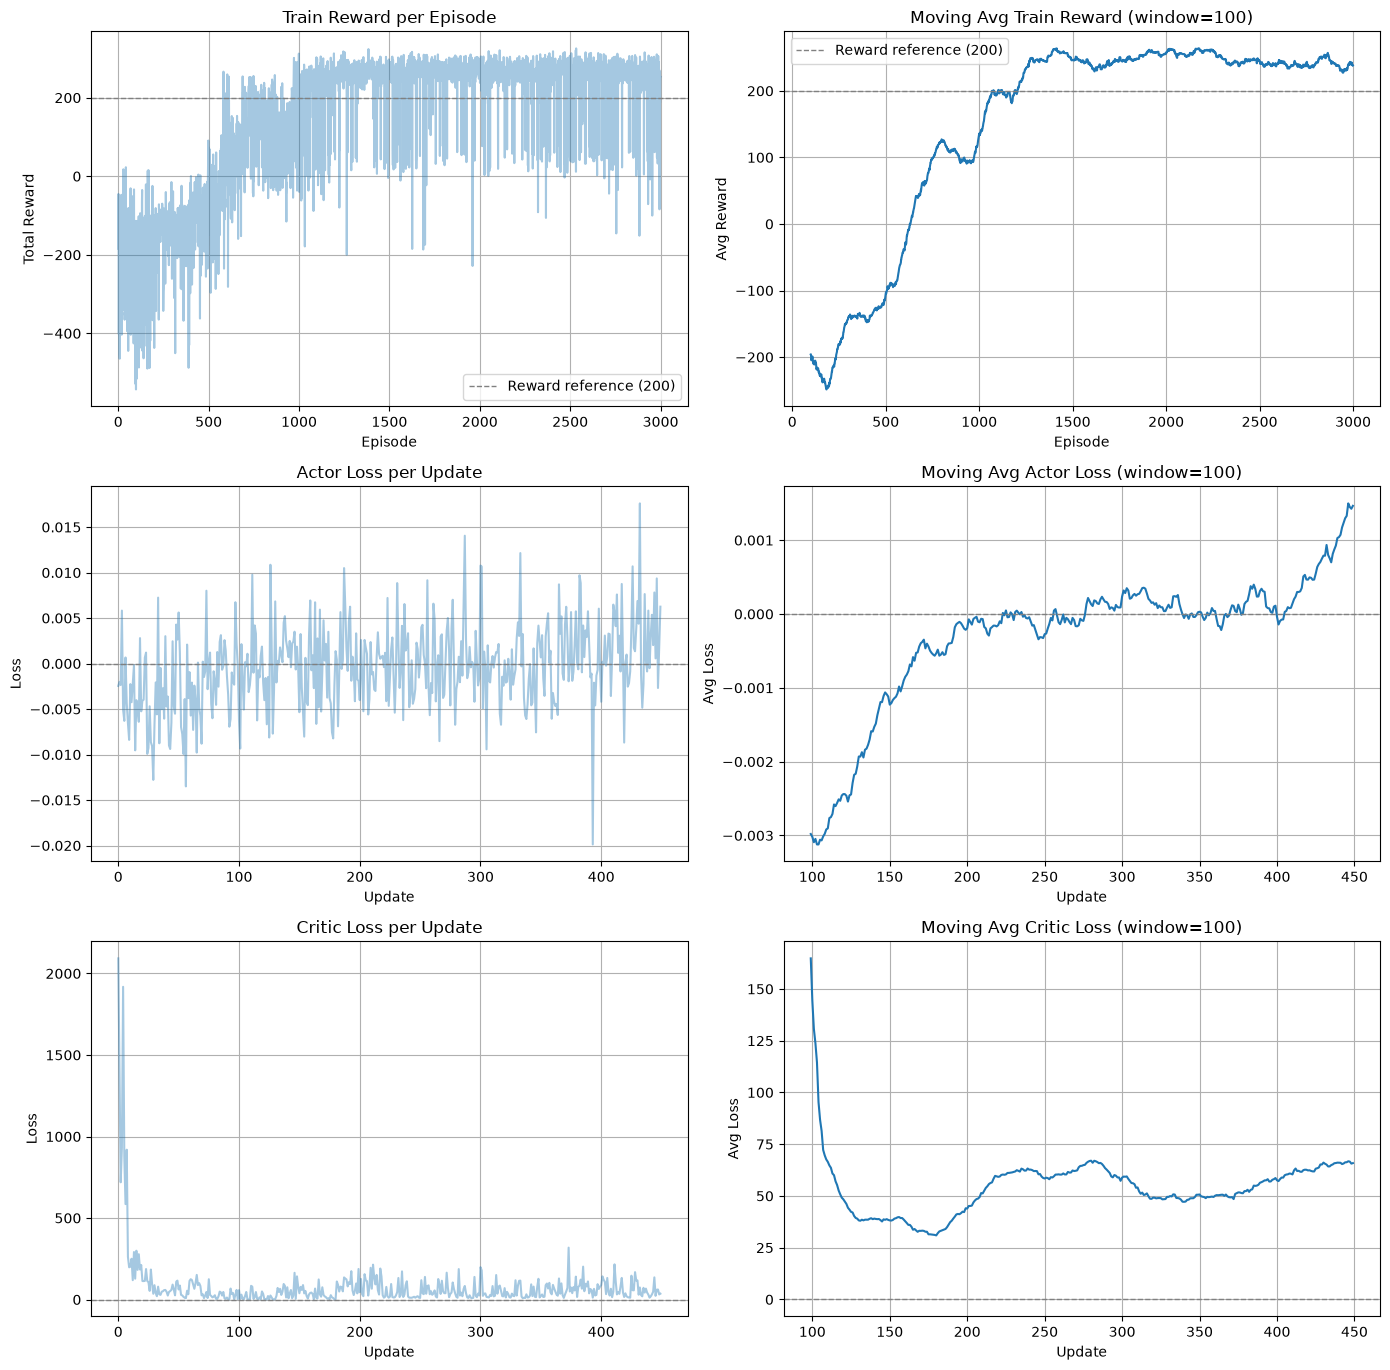


Testing agent...
Test Episode 1: 263.09
Test Episode 2: 270.93
Test Episode 3: 227.14
Test Episode 4: 261.10
Test Episode 5: 233.50


In [9]:
if __name__ == "__main__":

    # Set random seeds for reproducibility
    seed = 31
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    env_id = "LunarLander-v3"

    agent, rewards, actor_losses, critic_losses = train_agent(
        episodes=3000,
        update_freq=2048,
        env_id=env_id,
        seed=seed,
        lr=3e-4,
        gamma=0.99,
        gae_lambda=0.95,
        entropy_beta=0.000,
        clip_epsilon=0.2,
        ppo_epochs=10,
        batch_size=64,
    )

    print(f"\nFinal avg (last 100): {np.mean(rewards[-100:]):.2f}")
    print(f"Max reward: {max(rewards):.2f}")

    solve_line = 200
    plot_results(rewards, actor_losses=actor_losses, critic_losses=critic_losses, solved_y=solve_line)

    print("\nTesting agent...")
    test_agent(agent, env_id=env_id, episodes=5, render=True)

In [ ]:
if __name__ == "__main__":

    # Set random seeds for reproducibility
    seed = 31
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    env_id = "CartPole-v1"

    agent, rewards, actor_losses, critic_losses = train_agent(
        episodes=2000,
        update_freq=1024,
        env_id=env_id,
        seed=seed,
        lr=5e-4,
        gamma=0.99,
        gae_lambda=0.95,
        entropy_beta=0.001,
        clip_epsilon=0.1,
        ppo_epochs=5,
        batch_size=64,
    )

    print(f"\nFinal avg (last 100): {np.mean(rewards[-100:]):.2f}")
    print(f"Max reward: {max(rewards):.2f}")

    solve_line = 500
    plot_results(rewards, actor_losses=actor_losses, critic_losses=critic_losses, solved_y=solve_line)

    print("\nTesting agent...")
    test_agent(agent, env_id=env_id, episodes=5, render=True)

In [ ]:
if __name__ == "__main__":

    # Set random seeds for reproducibility
    seed = 31
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    env_id = "Blackjack-v1"

    agent, rewards, actor_losses, critic_losses = train_agent(
        episodes=100000,
        update_freq=1024,
        env_id=env_id,
        seed=seed,
        lr=3e-4,
        gamma=0.99,
        gae_lambda=0.95,
        entropy_beta=0.01,
        clip_epsilon=0.2,
        ppo_epochs=10,
        batch_size=64,
    )

    print(f"\nFinal avg (last 100): {np.mean(rewards[-100:]):.2f}")
    print(f"Max reward: {max(rewards):.2f}")

    solve_line = None
    plot_results(rewards, actor_losses=actor_losses, critic_losses=critic_losses, solved_y=solve_line)

    print("\nTesting agent...")
    test_agent(agent, env_id=env_id, episodes=5, render=True)

## Part 6: Bonus 🌟: Try out Atari Environments
---

### Task 6.1 ⚙️: 

**Instructions:**
1. Install packages needed to run Atari environments.

In [ ]:
import sys
print(sys.executable)

!"{sys.executable}" -m pip install ale-py opencv-python autorom
!"{sys.executable}" -m pip install --upgrade "gymnasium[atari]"

!AutoROM --accept-license

### Task 6.2 ⚙️: 

**Instructions:**
1. Check if the Atari environment runs correctly by creating an instance and resetting it. Run the following code, and ensure no errors occur.

In [ ]:
import sys
import gymnasium as gym
import ale_py

print("Python exec:", sys.executable)
print("ale_py version:", ale_py.__version__)

# 1. See if Gym knows about any ALE environments
env_ids = list(gym.envs.registry.keys())
ale_envs = [eid for eid in env_ids if eid.startswith("ALE/")]
print("Discovered ALE envs:", ale_envs[:15])

# 2. Try to actually build Assault
test_env_id = "ALE/Assault-v5"
try:
    env = gym.make(test_env_id, render_mode=None)
    obs, info = env.reset()
    print("[OK] Created env:", test_env_id)
    print("Observation shape:", obs.shape, "dtype:", obs.dtype)
    print("Action space:", env.action_space)
    env.close()
except Exception as e:
    print("[ERROR] Could not create", test_env_id)
    raise e

### Task 6.3 ⚙️: 

**Instructions:**
1. Run the following code to visualize the Atari Assault environment and ensure it works correctly.
2. Check the documentation of the Atari environments in Gymnasium to understand the action space and observation space. https://ale.farama.org/environments/assault/
3. If you are implementing a DRL agent for Atari games, how would you design the neural network architecture differently compared to simpler environments like CartPole or LunarLander?
4. What algorithm would you choose for training the agent in Atari environments, and why?

In [ ]:
import pygame


def find_action(actions, name):
    return actions.index(name) if name in actions else None

env = gym.make("ALE/Assault-v5", render_mode=None)
obs, info = env.reset()

pygame.init()

GAME_W, GAME_H = 160, 210
SCALE = 3
WIN_W, WIN_H = GAME_W * SCALE, GAME_H * SCALE + 60

screen = pygame.display.set_mode((WIN_W, WIN_H))
pygame.display.set_caption("Manual Atari Control (Assault) - replayable")
clock = pygame.time.Clock()
font = pygame.font.Font(None, 24)

actions = env.unwrapped.get_action_meanings()
print("Actions:", actions)

ACT_NOOP       = find_action(actions, "NOOP")
ACT_FIRE       = find_action(actions, "FIRE")
ACT_LEFT       = find_action(actions, "LEFT")
ACT_RIGHT      = find_action(actions, "RIGHT")
ACT_UP         = find_action(actions, "UP")
ACT_LEFTFIRE   = find_action(actions, "LEFTFIRE")
ACT_RIGHTFIRE  = find_action(actions, "RIGHTFIRE")

episode_reward = 0.0
want_quit = False

while not want_quit:
    # ------ 1. poll events ------
    for event in pygame.event.get():
        if event.type == pygame.QUIT:
            want_quit = True
        elif event.type == pygame.KEYDOWN and event.key == pygame.K_ESCAPE:
            want_quit = True

    # ------ 2. read held keys ------
    keys = pygame.key.get_pressed()

    action = ACT_NOOP
    if keys[pygame.K_a] and ACT_LEFTFIRE is not None:
        action = ACT_LEFTFIRE
    elif keys[pygame.K_d] and ACT_RIGHTFIRE is not None:
        action = ACT_RIGHTFIRE
    elif keys[pygame.K_LEFT] and ACT_LEFT is not None:
        action = ACT_LEFT
    elif keys[pygame.K_RIGHT] and ACT_RIGHT is not None:
        action = ACT_RIGHT
    elif keys[pygame.K_SPACE] and ACT_FIRE is not None:
        action = ACT_FIRE
    elif keys[pygame.K_UP] and ACT_UP is not None:
        action = ACT_UP
    # else NOOP by default / down arrow is just NOOP

    # ------ 3. step env ------
    obs, reward, terminated, truncated, info = env.step(action)
    episode_reward += reward

    # check if this episode ended
    episode_done = terminated or truncated

    # ------ 4. render the current obs ------
    # obs is (210,160,3) (H,W,3). pygame wants (W,H,3)
    frame = np.transpose(obs, (1, 0, 2))  # (160,210,3)
    surf = pygame.surfarray.make_surface(frame)
    surf = pygame.transform.scale(surf, (GAME_W * SCALE, GAME_H * SCALE))

    screen.fill((0,0,0))
    screen.blit(surf, (0,0))

    # lives info (optional)
    lives = None
    if hasattr(env.unwrapped, "ale"):
        try:
            lives = env.unwrapped.ale.lives()
        except Exception:
            lives = None

    # HUD text
    hud_lines = [
        f"Action: {actions[action]} (idx {action})",
        f"Step reward: {reward}",
        f"Episodic return: {episode_reward:.1f}",
        f"Lives: {lives if lives is not None else 'N/A'}",
        "ESC to quit. Game auto-resets on death.",
    ]
    y0 = GAME_H * SCALE + 5
    for i, txt in enumerate(hud_lines):
        label = font.render(txt, True, (255,255,255))
        screen.blit(label, (5, y0 + i*18))

    pygame.display.flip()

    # ------ 5. if episode finished, auto-reset instead of freezing ------
    if episode_done:
        # print to console so you can see your score for that life/run
        print(f"[EPISODE DONE] return = {episode_reward:.1f}")
        obs, info = env.reset()
        episode_reward = 0.0

    # ------ 6. keep loop responsive ------
    clock.tick(60)

env.close()
pygame.quit()
print("Exited cleanly.")